# Кластеризация и техники понижения размерности. Часть I

## K-Means и EM-алгоритм: практика

In [2]:
#Загрузка необходимых библиотек
import numpy as np 
import pandas as pd

#Загружаем data frame
df_teens = pd.read_csv('data/snsdata.csv')

display(df_teens.head())
display(df_teens.info())

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2006,M,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,F,18.801,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2006,M,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2006,F,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2006,NaN,18.995,10,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 40 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   gradyear      30000 non-null  int64  
 1   gender        27276 non-null  str    
 2   age           24914 non-null  float64
 3   friends       30000 non-null  int64  
 4   basketball    30000 non-null  int64  
 5   football      30000 non-null  int64  
 6   soccer        30000 non-null  int64  
 7   softball      30000 non-null  int64  
 8   volleyball    30000 non-null  int64  
 9   swimming      30000 non-null  int64  
 10  cheerleading  30000 non-null  int64  
 11  baseball      30000 non-null  int64  
 12  tennis        30000 non-null  int64  
 13  sports        30000 non-null  int64  
 14  cute          30000 non-null  int64  
 15  sex           30000 non-null  int64  
 16  sexy          30000 non-null  int64  
 17  hot           30000 non-null  int64  
 18  kissed        30000 non-null  int64  

None

### Задание 4.1

Мы будем реализовывать алгоритм только на признаках, которые заключают в себе ключевые слова, встречающиеся в сообщениях подростка. Удалите все остальные признаки. Какова размерность вашего текущего набора данных?

In [3]:
# Удаляем ненужные признаки (первые 4 колонки)
df_teens = df_teens.drop(columns=['gradyear', 'gender', 'age', 'friends'])

# Выводим размерность текущего набора данных (количество строк и столбцов)
print(f"Размерность набора данных: {df_teens.shape}")

Размерность набора данных: (30000, 36)


### Задание 4.2
Теперь нормализуйте данные с помощью StandardScaler(). Для получившейся матрицы нормализованных признаков выведите самое первое значение в самой первой строке (X_norm[0][0]). Ответ округлите до двух знаков после точки-разделителя.

In [4]:
from sklearn.preprocessing import StandardScaler

# 1. Инициализируем scaler
scaler = StandardScaler()

# 2. Применяем нормализацию ко всему датасету
X_norm = scaler.fit_transform(df_teens)

# 3. Выводим самое первое значение (первая строка, первый столбец)
first_value = X_norm[0][0]

print(f"Самое первое значение в матрице: {round(first_value, 2)}")

Самое первое значение в матрице: -0.33


### Задание 4.3
Реализуйте алгоритм k-means c девятью кластерами. В качестве значения параметра random_state возьмите число 42. Выведите получившееся значение инерции (model.inertia_). Ответ округлите до двух знаков после точки-разделителя.


In [16]:
from sklearn.cluster import KMeans

# 1. Инициализируем KMeans с 9 кластерами и random_state=42
kmeans = KMeans(n_clusters=9, random_state=42)

# 2. Обучаем модель на нормализованных данных
kmeans.fit(X_norm)

# 3. Выводим инерцию, округленную до двух знаков
print(f"Значение инерции: {round(kmeans.inertia_, 2)}")

Значение инерции: 856276.7


### Задание 4.4
Сколько подростков относится к наиболее многочисленному кластеру?

А сколько — к самому малочисленному?

In [18]:
# Считаем количество объектов в каждом кластере
cluster_counts = pd.Series(kmeans.labels_).value_counts()

# Выводим результаты
print("Количество подростков в каждом кластере:")
print(cluster_counts.sort_index())

print(f"\nНаиболее многочисленный кластер (№{cluster_counts.idxmax()}): {cluster_counts.max()} человек")
print(f"Самый малочисленный кластер (№{cluster_counts.idxmin()}): {cluster_counts.min()} человек")

Количество подростков в каждом кластере:
0     2201
1    19599
2     4284
3      902
4      941
5      851
6        1
7      467
8      754
Name: count, dtype: int64

Наиболее многочисленный кластер (№1): 19599 человек
Самый малочисленный кластер (№6): 1 человек


### Задание 4.5 
1. Мы выделили девять кластеров, но, возможно, это далеко не оптимальное количество. Давайте попробуем применить разные методы для нахождения числа кластеров. Будем выбирать количество кластеров из диапазона от 3 до 9.

Для начала примените метод локтя. Каким в этом случае будет оптимальное число кластеров? Если оно не идентифицируется однозначно, запишите количество кластеров, при котором достигается наименьшая инерция.

2. Теперь попробуйте подобрать оптимальное количество кластеров с помощью коэффициента силуэта. Каким оно будет?

Если невозможно однозначно определить количество кластеров, при котором достигается максимальное значение коэффициента силуэта, выберите наименьшее количество кластеров из подходящих.

Кластеров: 3, Инерция: 994114.72
Кластеров: 4, Инерция: 965041.28
Кластеров: 5, Инерция: 943134.13
Кластеров: 6, Инерция: 917113.38
Кластеров: 7, Инерция: 899316.34
Кластеров: 8, Инерция: 872318.48
Кластеров: 9, Инерция: 856276.70


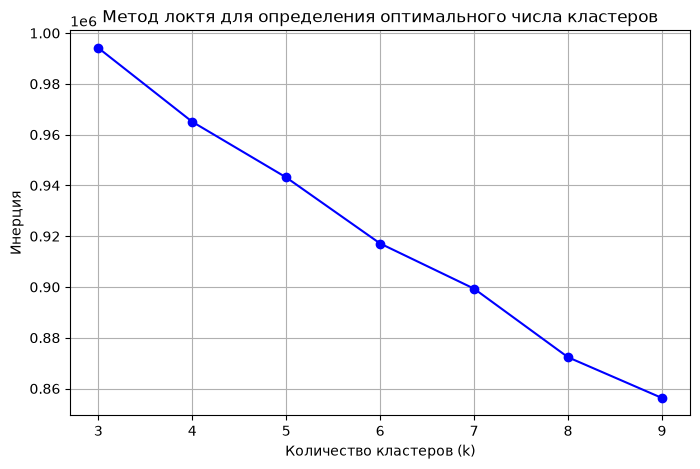

In [20]:
import matplotlib.pyplot as plt

inertias = []
K_range = range(3, 10)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_norm)
    inertias.append(kmeans_temp.inertia_)
    print(f"Кластеров: {k}, Инерция: {kmeans_temp.inertia_:.2f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='b')
plt.title('Метод локтя для определения оптимального числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция')
plt.xticks(K_range)
plt.grid(True)
plt.show()

Кластеров: 3, Silhouette Score: 0.3254
Кластеров: 4, Silhouette Score: 0.3273
Кластеров: 5, Silhouette Score: 0.3167
Кластеров: 6, Silhouette Score: 0.2906
Кластеров: 7, Silhouette Score: 0.2848
Кластеров: 8, Silhouette Score: 0.2518
Кластеров: 9, Silhouette Score: 0.2519


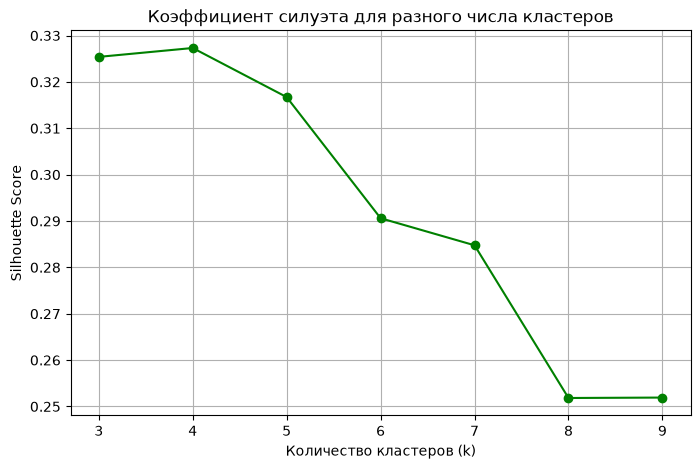

In [21]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(3, 10)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_norm)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(X_norm, labels)
    silhouette_scores.append(score)
    print(f"Кластеров: {k}, Silhouette Score: {score:.4f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='g')
plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

### Задание 4.6
Мы будем использовать результаты, полученные в предыдущем задании с помощью коэффициента силуэта.

Реализуйте сегментацию подростков на выбранном количестве кластеров.

Для каждого кластера составьте топ-10 самых частых слов, назовём их ключевыми. Для этого сгруппируйте данные по кластерам, в каждом кластере вычислите среднее по каждому признаку, отсортируйте данные по убыванию и выделите первые 10 строк.

Найдите среди ключевых слов те, которые характерны для каждого кластера, то есть встречаются в каждом из них.

In [22]:
# 1. Обучаем K-Means с 3 кластерами
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_final.fit(X_norm)

# 2. Добавляем метки кластеров в наш датафрейм (до нормализации, чтобы сохранить исходные частоты)
df_teens_clustered = df_teens.copy()
df_teens_clustered['cluster'] = kmeans_final.labels_

# 3. Группируем по кластерам и считаем средние значения
# Так как признаки — это частоты слов, среднее покажет, насколько часто слово встречается в кластере
cluster_means = df_teens_clustered.groupby('cluster').mean()

# 4. Для каждого кластера находим топ-10 слов
top_10_words = {}
for cluster_id in cluster_means.index:
    # Сортируем признаки по убыванию среднего значения и берем первые 10
    top_words = cluster_means.loc[cluster_id].sort_values(ascending=False).head(10)
    top_10_words[cluster_id] = top_words.index.tolist()
    
    print(f"\n--- Топ-10 слов для кластера {cluster_id} ---")
    for word, val in top_words.items():
        print(f"{word}: {val:.2f}")


--- Топ-10 слов для кластера 0 ---
music: 0.58
god: 0.33
dance: 0.25
band: 0.24
hair: 0.20
shopping: 0.19
cute: 0.18
rock: 0.16
soccer: 0.15
football: 0.15

--- Топ-10 слов для кластера 1 ---
music: 1.05
dance: 0.99
shopping: 0.93
god: 0.89
cute: 0.79
hair: 0.73
church: 0.67
basketball: 0.67
mall: 0.66
football: 0.60

--- Топ-10 слов для кластера 2 ---
hair: 3.23
sex: 2.43
music: 2.26
kissed: 1.57
die: 1.21
rock: 1.11
god: 1.00
band: 0.97
dance: 0.97
drugs: 0.95


### Задание 4.7
Итак, с k-means мы потренировались — теперь перейдём к EM-алгоритму.

Реализуйте EM-алгоритм (GaussianMixture) для такого же количества кластеров, как и в предыдущем задании. В качестве значения параметра random_state возьмите число 42.

Сколько подростков алгоритм отнёс к самому многочисленному кластеру?

In [29]:
from sklearn.mixture import GaussianMixture
import pandas as pd

# 1. Инициализируем и обучаем модель
# n_components — это аналог n_clusters в K-Means
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X_norm)

# 2. Получаем метки кластеров для каждого объекта
labels_gmm = gmm.predict(X_norm)

# 3. Считаем, сколько объектов в каждом кластере
cluster_counts_gmm = pd.Series(labels_gmm).value_counts()

# 4. Выводим результаты
print("Количество подростков в каждом кластере (GMM):")
print(cluster_counts_gmm)

print(f"\nСамый многочисленный кластер: {cluster_counts_gmm.max()} человек")

Количество подростков в каждом кластере (GMM):
0    20670
2     6456
1     2874
Name: count, dtype: int64

Самый многочисленный кластер: 20670 человек


### Задание 4.8
В одном из кластеров оказался всего один человек. Давайте узнаем, что это за подросток и чем он(а) интересуется.

Отметьте три слова, которые чаще всего встречаются в сообщениях этого подростка:




## Итоговая практика по алгоритмам кластеризации

In [32]:
#Загрузка необходимых библиотек
import numpy as np 
import pandas as pd
#Загрузка датасета
cc_df = pd.read_csv('data/cc_data.csv')
#Проверка датасета
display(cc_df.head())
display(cc_df.info())

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

None

## Задание 7.2
Теперь приступим к анализу данных. По традиции начнём его с проверки данных на наличие пропущенных значений. Сколько всего пропусков в данных?

In [33]:
# Считаем общее количество пропусков в датафрейме
total_missing = cc_df.isna().sum().sum()

print(f"Всего пропусков в данных: {total_missing}")

Всего пропусков в данных: 314


### Задание 7.3
Заполните все пропуски средними арифметическими для признаков. Каким будет среднее арифметическое для признака MINIMUM_PAYMENTS (если считать после заполнения пропущенных значений)? Округлите результат до двух знаков после точки-разделителя.

In [34]:
# 1. Заполняем пропуски средними значениями (только для числовых колонок)
cc_df = cc_df.fillna(cc_df.mean(numeric_only=True))

# 2. Считаем среднее для MINIMUM_PAYMENTS после заполнения
mean_min_payments = cc_df['MINIMUM_PAYMENTS'].mean()

print(f"Среднее значение MINIMUM_PAYMENTS: {round(mean_min_payments, 2)}")

Среднее значение MINIMUM_PAYMENTS: 864.21


### Задание 7.4

Теперь нормализуйте данные с помощью StandardScaler(). Для получившейся матрицы нормализованных признаков выведите самое первое значение в самой первой строке (X_norm[0][0]). Округлите до двух знаков после точки-разделителя.

Не забудьте предварительно удалить признак CUST_ID — он не поможет при кластеризации, так как не несёт никакой содержательной информации.

In [35]:
from sklearn.preprocessing import StandardScaler

# 1. Удаляем CUST_ID
cc_df_clean = cc_df.drop(columns=['CUST_ID'])

# 2. Инициализируем scaler и применяем его ко всем данным
scaler = StandardScaler()
X_norm = scaler.fit_transform(cc_df_clean)

# 3. Выводим самое первое значение в матрице (первая строка, первый столбец)
first_value = X_norm[0][0]

print(f"Первое значение в матрице: {round(first_value, 2)}")

Первое значение в матрице: -0.73


### Задание 7.5

Теперь можем приступать к кластеризации. Начнём с самого простого и популярного метода — k-means. Для того чтобы его применить, необходимо узнать число кластеров. Наилучший способ сделать это — применить коэффициент силуэта. Найдите с его помощью оптимальное количество кластеров, перебрав диапазон от 2 до 9 включительно. В этом и следующем заданиях для параметра random_state возьмём значение 42, параметр init='random'.

Кластеров: 2, Silhouette Score: 0.2095
Кластеров: 3, Silhouette Score: 0.2506
Кластеров: 4, Silhouette Score: 0.1976
Кластеров: 5, Silhouette Score: 0.1930
Кластеров: 6, Silhouette Score: 0.2028
Кластеров: 7, Silhouette Score: 0.2150
Кластеров: 8, Silhouette Score: 0.2130
Кластеров: 9, Silhouette Score: 0.2153


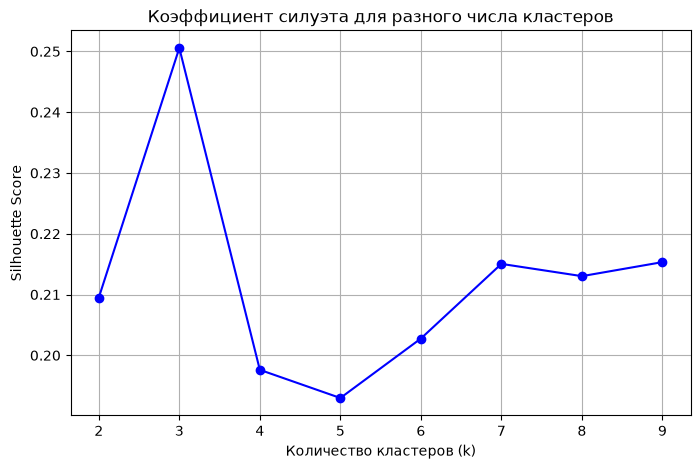


Оптимальное количество кластеров: 3


In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
    # Инициализируем K-Means с параметрами из задания
    kmeans = KMeans(n_clusters=k, init='random', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_norm)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(X_norm, labels)
    silhouette_scores.append(score)
    print(f"Кластеров: {k}, Silhouette Score: {score:.4f}")

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

# Находим k с максимальным силуэтом
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nОптимальное количество кластеров: {best_k}")

### Задание 7.6
Теперь реализуем непосредственно кластеризацию k-means с оптимальным количеством кластеров, которое мы определили в предыдущем задании.

Сколько человек оказалось в самой малочисленной группе?

In [37]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Обучаем K-Means с 3 кластерами и параметрами из задания
kmeans_final = KMeans(n_clusters=3, init='random', random_state=42, n_init=10)
kmeans_final.fit(X_norm)

# 2. Получаем метки кластеров и считаем их размеры
labels = kmeans_final.labels_
cluster_counts = pd.Series(labels).value_counts()

print("Количество человек в каждом кластере:")
print(cluster_counts.sort_index())

# 3. Находим самую малочисленную группу
min_cluster_size = cluster_counts.min()

print(f"\nСамая малочисленная группа: {min_cluster_size} человек")

Количество человек в каждом кластере:
0    1235
1    1596
2    6119
Name: count, dtype: int64

Самая малочисленная группа: 1235 человек


### Задание 7.7
Попробуем применить DBSCAN. Для начала реализуйте его с параметрами по умолчанию.

Сколько кластеров было выделено?

In [38]:
from sklearn.cluster import DBSCAN
import numpy as np

# 1. Инициализируем и обучаем DBSCAN с параметрами по умолчанию
dbscan = DBSCAN()
labels_dbscan = dbscan.fit_predict(X_norm)

# 2. Смотрим на уникальные метки
unique_labels = set(labels_dbscan)

# 3. Считаем количество кластеров (исключая шум, который обозначается как -1)
# Если -1 есть в метках, вычитаем 1
n_clusters = len(unique_labels - {-1}) if -1 in unique_labels else len(unique_labels)

print(f"Уникальные метки: {unique_labels}")
print(f"Количество выделенных кластеров (без учета шума): {n_clusters}")

Уникальные метки: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, -1}
Количество выделенных кластеров (без учета шума): 38


### Задание 7.8
В предыдущем задании получилось очень много кластеров. Возможно, это случилось потому, что мы взяли параметры по умолчанию, а результат алгоритма DBSCAN, как вы помните, очень чувствителен к ним.

Давайте попробуем с помощью цикла перебрать параметр eps по значениям, заданным как np.arange(0.1,3,0.2), а параметр min_samples — по значениям, заданным как range(1,20,4). Найдите комбинацию, которая даёт максимальное значение коэффициента силуэта.

Коэффициент силуэта (округлите до двух знаков после точки-разделителя):

In [39]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

best_score = -1
best_params = {}

# Перебираем параметры
for eps in np.arange(0.1, 3, 0.2):
    for min_samples in range(1, 20, 4):
        # Обучаем DBSCAN
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_norm)
        
        # Проверяем, что кластеров больше одного (игнорируя шум -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters > 1:
            score = silhouette_score(X_norm, labels)
            
            # Если нашли лучший результат — запоминаем
            if score > best_score:
                best_score = score
                best_params = {'eps': eps, 'min_samples': min_samples, 'n_clusters': n_clusters}

print(f"Лучший коэффициент силуэта: {round(best_score, 2)}")
print(f"Лучшие параметры: {best_params}")

Лучший коэффициент силуэта: 0.4
Лучшие параметры: {'eps': 1.7000000000000004, 'min_samples': 5, 'n_clusters': 2}


### Задание 7.9
Теперь давайте реализуем агломеративную иерархическую кластеризацию. Переберите количество кластеров в диапазоне от 3 до 9 включительно и найдите то их число, которое будет давать максимальный коэффициент силуэта.

In [43]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

silhouette_scores_agg = []
K_range = range(3, 10)

for k in K_range:
    # Инициализируем и обучаем модель
    agg_model = AgglomerativeClustering(n_clusters=k)
    labels = agg_model.fit_predict(X_norm)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(X_norm, labels)
    silhouette_scores_agg.append(score)
    print(f"Кластеров: {k}, Silhouette Score: {score:.4f}")

# Находим k с максимальным силуэтом
best_k_agg = K_range[silhouette_scores_agg.index(max(silhouette_scores_agg))]
print(f"\nОптимальное количество кластеров (максимальный силуэт): {best_k_agg}")

Кластеров: 3, Silhouette Score: 0.1731
Кластеров: 4, Silhouette Score: 0.1547
Кластеров: 5, Silhouette Score: 0.1581
Кластеров: 6, Silhouette Score: 0.1734
Кластеров: 7, Silhouette Score: 0.1564
Кластеров: 8, Silhouette Score: 0.1520
Кластеров: 9, Silhouette Score: 0.1537

Оптимальное количество кластеров (максимальный силуэт): 6


### Задание 7.10
Сколько будет наблюдений в самом многочисленном классе, если мы обучим на наших данных модель агломеративной иерархической кластеризации с количеством кластеров, полученным в предыдущем задании?

In [44]:
import pandas as pd

# 1. Обучаем модель с 6 кластерами
agg_model_final = AgglomerativeClustering(n_clusters=6)
agg_labels = agg_model_final.fit_predict(X_norm)

# 2. Считаем количество объектов в каждом кластере
cluster_counts_agg = pd.Series(agg_labels).value_counts()

print("Количество наблюдений в каждом кластере:")
print(cluster_counts_agg.sort_index())

# 3. Находим самый многочисленный кластер
max_cluster_size = cluster_counts_agg.max()
print(f"\nСамый многочисленный кластер содержит: {max_cluster_size} наблюдений")

Количество наблюдений в каждом кластере:
0    3946
1    2931
2     864
3     464
4      23
5     722
Name: count, dtype: int64

Самый многочисленный кластер содержит: 3946 наблюдений


Давайте визуализируем результаты кластеризации k-means, отобразив два признака — количество покупок и кредитный лимит:

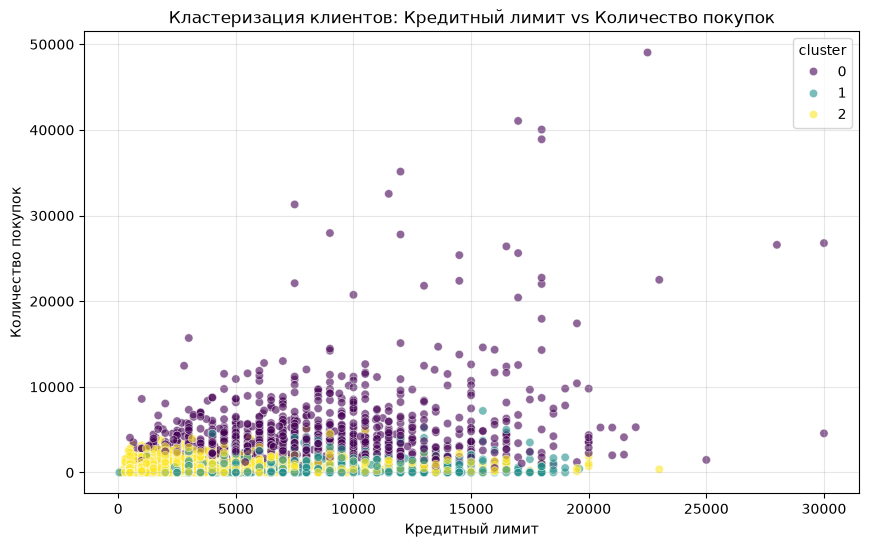

: 

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Обучаем KMeans (на всякий случай переобучим, чтобы у всех были одинаковые метки)
kmeans = KMeans(n_clusters=3, init='random', random_state=42, n_init=10)
kmeans.fit(X_norm)

# 2. Сохраняем метки в наш датафрейм (используем английские буквы!)
cc_df['cluster'] = kmeans.labels_

# 3. Строим график
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cc_df, x='CREDIT_LIMIT', y='PURCHASES', hue='cluster', palette='viridis', alpha=0.6)
plt.title('Кластеризация клиентов: Кредитный лимит vs Количество покупок')
plt.xlabel('Кредитный лимит')
plt.ylabel('Количество покупок')
plt.grid(True, alpha=0.3)
plt.show()